# Acting Through a Body

*The Mathematics of Machine Intelligence · Chapter 20*

Plan a move from a prediction, correct only what matters, and see what a delay or a changed world does to the plan.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask for the delay, the gain, and what the predicted feedback is. For a plan from a remembered target, subtract the estimated last move. For a gap between prediction and sensor, say that the residual alone cannot name its cause. For late feedback, compare the plain loop with a loop that models the delay, and for a changed world use an error-driven update and check the aftereffect. Quote counts with their exact range.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 20, Acting Through a Body: executable mathematics and reader-facing teaching content."""
import math
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels():
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained')
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
TARGET = (10.0, 8.0)

def second_jump(target, first_jump, deficit):
    """Plan m2 = r2 - s1_hat when a share `deficit` of the first-jump signal is lost (1 means zero is substituted)."""
    if not 0 <= deficit <= 1:
        raise ValueError('Deficit is a share between 0 and 1.')
    est = (first_jump[0] * (1 - deficit), first_jump[1] * (1 - deficit))
    planned = (target[0] - est[0], target[1] - est[1])
    needed = (target[0] - first_jump[0], target[1] - first_jump[1])
    end = (first_jump[0] + planned[0], first_jump[1] + planned[1])
    shift = (end[0] - target[0], end[1] - target[1])
    return {'estimate': est, 'planned': planned, 'needed': needed, 'end': end, 'shift': shift}

def double_step_picture(deficit=0.19, amplitude=10):
    first = (float(amplitude), 0.0)
    data = second_jump(TARGET, first, deficit)
    fig, ax = panels()
    a = ax[0]
    a.annotate('', xy=first, xytext=(0, 0), arrowprops={'arrowstyle': '-|>', 'color': NAVY, 'linewidth': 2.2})
    a.annotate('', xy=TARGET, xytext=first, arrowprops={'arrowstyle': '-|>', 'color': TEAL, 'linewidth': 1.8, 'linestyle': 'dashed'})
    a.annotate('', xy=data['end'], xytext=first, arrowprops={'arrowstyle': '-|>', 'color': TERRA, 'linewidth': 2.2})
    a.plot([0], [0], marker='o', color=GREY, markersize=8)
    a.plot([TARGET[0]], [TARGET[1]], marker='*', color=GOLD, markersize=17, markeredgecolor=DARK_GOLD)
    a.plot([data['end'][0]], [data['end'][1]], marker='x', color=TERRA, markersize=10, markeredgewidth=2.5)
    tag(a, 0, -1.4, 'start', color=GREY)
    tag(a, first[0] / 2, 0.9, 'first jump', color=NAVY)
    tag(a, TARGET[0] - 1.0, TARGET[1] + 0.2, 'remembered target', color=DARK_GOLD, ha='right')
    tag(a, (first[0] + data['end'][0]) / 2 + 1.5, (first[1] + data['end'][1]) / 2 - 1.1, 'planned second jump', color=TERRA, ha='left')
    a.set(xlim=(-2, 28), ylim=(-3, 11.5), xlabel='across (made-up units)', ylabel='up (made-up units)', title='Where the second jump lands')
    grid = np.linspace(0, 1, 101)
    for amp, style, colour in [(5, 'dotted', GREY), (10, 'solid', TEAL), (15, 'dashed', TERRA)]:
        chosen = amp == amplitude
        ax[1].plot(grid, grid * amp, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'first jump {amp}')
    ring(ax[1], deficit, deficit * amplitude)
    for share, label, y in [(0.1, 'all 22 cases, about 10 percent', 13.6), (0.19, '11 clear cases, 19 percent', 15.8)]:
        ax[1].axvline(share, color=DARK_GOLD, linewidth=1, linestyle='dotted')
        tag(ax[1], share + 0.012, y, label, color=DARK_GOLD, fontsize=8.5, ha='left')
    ax[1].set(xlabel='share of the first-jump signal lost', ylabel='miss of the second jump (units)', title='The miss grows with the loss', xlim=(-0.02, 1.02), ylim=(-0.5, 16.5))
    ax[1].legend(fontsize=9, loc='lower right')
    miss = math.hypot(*data['shift'])
    metrics = {'Planned second jump (across, up)': f"({sig(data['planned'][0])}, {sig(data['planned'][1])})", 'Needed second jump (across, up)': f"({sig(data['needed'][0])}, {sig(data['needed'][1])})", 'Miss of the end point (units)': sig(miss), 'Share of the total-loss miss': sig(deficit)}
    summary = f"A first jump of {amplitude} units with {sig(deficit)} of its signal lost makes the planned second jump ({sig(data['planned'][0])}, {sig(data['planned'][1])}) instead of the needed ({sig(data['needed'][0])}, {sig(data['needed'][1])}). The end point misses by {sig(miss)} units, {sig(deficit)} of the {amplitude}-unit miss that total loss would cause."
    calc = f"Estimate = (1 - {sig(deficit)}) x {amplitude} = {sig(data['estimate'][0])}. Plan = target - estimate = ({TARGET[0]:g} - {sig(data['estimate'][0])}, {TARGET[1]:g} - 0) = ({sig(data['planned'][0])}, {sig(data['planned'][1])}). Needed = ({TARGET[0]:g} - {amplitude}, {TARGET[1]:g}) = ({sig(data['needed'][0])}, {sig(data['needed'][1])}). Miss = {sig(deficit)} x {amplitude} = {sig(miss)}."
    return (fig, metrics, {'summary': summary, 'calculation': calc})
PREDICTED = 6.0

def residual_split(observed, predicted, push):
    """e = s_obs - f(c) = w + [rho(a) - f(c)]; returns the residual, the outside push and the prediction error."""
    residual = observed - predicted
    return {'residual': residual, 'push': push, 'prediction_error': residual - push}

def residual_picture(push=2, residual=2):
    observed = PREDICTED + residual
    data = residual_split(observed, PREDICTED, push)
    err = data['prediction_error']
    fig, ax = panels()
    a = ax[0]
    a.bar([0], [push], color=TEAL, width=0.55, label='outside push w')
    a.bar([0], [err], bottom=[push if (push >= 0) == (err >= 0) else 0], color=TERRA, width=0.55, label='prediction error')
    a.bar([1], [residual], color=NAVY, width=0.55)
    a.axhline(0, color=GREY, linewidth=1)
    tag(a, 0, max(push, 0, push + err if (push >= 0) == (err >= 0) else 0) + 0.35, f'w {sig(push)} + error {sig(err)}', va='bottom', color=NAVY, fontsize=9)
    tag(a, 1, max(residual, 0) + 0.35, f'residual {sig(residual)}', va='bottom', color=NAVY, fontsize=9)
    a.set(xticks=[0, 1], xticklabels=['one possible split', 'what is seen'], ylim=(-5, 8), ylabel='size of the gap', title=f'Observed {sig(observed)} minus predicted {sig(PREDICTED)}')
    a.legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
    grid = np.linspace(-3, 6, 91)
    for r, style, colour in [(0, 'dotted', GREY), (2, 'solid', TEAL), (4, 'dashed', TERRA)]:
        chosen = r == residual
        ax[1].plot(grid, r - grid, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'residual {r}')
    ring(ax[1], push, err)
    ax[1].plot([0, residual], [residual, 0], linestyle='none', marker='s', markersize=6, color=DARK_GOLD)
    tag(ax[1], 0.1, residual + 0.7, 'no push', fontsize=8.5, color=DARK_GOLD, ha='left')
    tag(ax[1], residual - 0.25, -0.95, 'perfect prediction', fontsize=8.5, color=DARK_GOLD, ha='right')
    ax[1].set(xlabel='outside push w', ylabel='prediction error', title='Every point on a line fits the same gap', xlim=(-3, 6), ylim=(-3, 6.5))
    ax[1].legend(fontsize=9, loc='upper right')
    metrics = {'Observed feedback': sig(observed), 'Predicted feedback': sig(PREDICTED), 'Residual (observed minus predicted)': sig(residual), 'Prediction error left over': sig(err)}
    if residual == 0:
        tell = 'A residual of 0 does not rule out a push: a push of w with a prediction error of minus w cancels it.'
    else:
        tell = 'The same residual comes from an outside push with a perfect prediction, from no push with a prediction error, or any mix.'
    summary = f'Observed {sig(observed)} against predicted {sig(PREDICTED)} leaves a residual of {sig(residual)}. With an outside push of {sig(push)}, the prediction must be off by {sig(err)}. {tell}'
    calc = f'e = {sig(observed)} - {sig(PREDICTED)} = {sig(residual)}. e = w + [rho(a) - f(c)], so {sig(residual)} = {sig(push)} + {sig(err)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
DELAY = 0.2
STEP = 0.005
HORIZON = 12.0

def simulate_loop(gain, model_error=0.0, smith=True, delay=DELAY, dt=STEP, horizon=HORIZON, target=1.0):
    """Integrator plant x' = u with a sensor that reports x delayed by `delay`; u = gain x (target - feedback).
    Plain: feedback is the late report. Smith: late report + x(t) - x(t - modelled delay), the plant model being exact."""
    d_steps = int(round(delay / dt))
    m_steps = int(round((delay + model_error) / dt))
    n_steps = int(round(horizon / dt))
    x = np.zeros(n_steps + 1)
    for n in range(n_steps):
        late = x[n - d_steps] if n - d_steps >= 0 else 0.0
        if smith:
            model_late = x[n - m_steps] if n - m_steps >= 0 else 0.0
            feedback = late + x[n] - model_late
        else:
            feedback = late
        x[n + 1] = x[n] + dt * gain * (target - feedback)
    return x

def late_wobble(x, target=1.0, tail_seconds=2.0, dt=STEP):
    tail = int(round(tail_seconds / dt))
    return float(np.max(np.abs(x[-tail:] - target)))

@lru_cache(maxsize=None)
def wobble_for(gain, model_error, smith):
    return late_wobble(simulate_loop(gain, model_error, smith))
SETTLE_LIMIT = 0.01
LONG_HORIZON = 60.0

@lru_cache(maxsize=None)
def loop_status(gain, model_error, smith):
    """'settles' if the last 2 s of the 12 s run stay within the limit; 'settles slowly' if only a 60 s run does; else 'does not settle'."""
    if late_wobble(simulate_loop(gain, model_error, smith)) < SETTLE_LIMIT:
        return 'settles'
    with np.errstate(over='ignore', invalid='ignore'):
        long_run = simulate_loop(gain, model_error, smith, horizon=LONG_HORIZON)
    if np.isfinite(long_run).all() and late_wobble(long_run) < SETTLE_LIMIT:
        return 'settles slowly'
    return 'does not settle'

def delay_picture(gain=10, model_error_ms=0):
    err = model_error_ms / 1000
    plain = simulate_loop(gain, 0.0, smith=False)
    smith = simulate_loop(gain, err, smith=True)
    plain_status = loop_status(float(gain), 0.0, False)
    smith_status = loop_status(float(gain), err, True)
    plain_ok = plain_status == 'settles'
    t = np.arange(len(plain)) * STEP
    fig, ax = panels()
    ax[0].plot(t, np.clip(plain, -0.5, 3), color=TERRA, linewidth=2, linestyle='dashed', label='plain feedback')
    ax[0].plot(t, np.clip(smith, -0.5, 3), color=NAVY, linewidth=2.6, label='Smith predictor')
    ax[0].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    ax[0].set(xlabel='time (s)', ylabel='position (target = 1)', title='Constructed plant: a late report', xlim=(0, 6), ylim=(-0.3, 2.6))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    if not plain_ok:
        tag(ax[0], 3, 2.35, 'plain loop swings out of range' if np.max(np.abs(plain)) > 3 else 'plain loop keeps swinging', color=TERRA, fontsize=9)
    gains = [2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 14, 16, 18, 20, 22]
    floor = 1e-06
    for label, e, use_smith, style, colour in [('plain', 0.0, False, 'dashed', TERRA), ('Smith, model 100 ms short', -0.1, True, 'dotted', GOLD), ('Smith, model right', 0.0, True, 'solid', TEAL), ('Smith, model 100 ms long', 0.1, True, 'dashdot', GREY)]:
        curve = [max(wobble_for(float(g), e, use_smith), floor) for g in gains]
        ax[1].plot(gains, np.clip(curve, floor, 1000.0), color=colour, linestyle=style, linewidth=2, label=label)
    ax[1].axhline(SETTLE_LIMIT, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 1.5, SETTLE_LIMIT * 1.9, 'wobble above this line:\nstill swinging at 12 s', fontsize=8.5, color=GREY, ha='left')
    current = max(wobble_for(float(gain), err, True), floor)
    ring(ax[1], gain, min(current, 1000.0))
    ax[1].set(xlabel='correction strength (gain, per second)', ylabel='wobble in the last 2 s (log scale)', title='Strong correction needs the right delay model', yscale='log', ylim=(5e-07, 2000.0))
    ax[1].legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    peak = lambda x, status: sig(max(float(np.max(x)) - 1, 0) * 100) if status != 'does not settle' else 'undefined (does not settle)'
    labels = {'settles': 'settles', 'settles slowly': 'settles slowly (stable, still swinging after 12 s)', 'does not settle': 'does not settle'}
    metrics = {'Plain loop': labels[plain_status], 'Plain overshoot (percent)': peak(plain, plain_status), 'Smith loop': labels[smith_status], 'Smith overshoot (percent)': peak(smith, smith_status)}
    limit = math.pi / (2 * DELAY)
    summary = f"At gain {gain:g} per second with a 0.2 s delay, the plain loop {labels[plain_status]} and the Smith loop with its delay model {model_error_ms:g} ms off {labels[smith_status]}. The plain loop's limit is gain pi/(2 x 0.2) = {sig(limit)}." + ('' if model_error_ms == 0 else " This constructed plant forgives a 100 ms model error more than the chapter's 1993 simulation did.")
    calc = f"Plant x' = u, report x(t - 0.2). Plain: u = gain x (1 - x(t - 0.2)), which settles only when gain x delay is below pi/2, so gain below {sig(limit)}. Smith with the right delay model: the loop sees x(t) itself, so x(t) = 1 - exp(-gain x t), settling for every gain. Euler steps of {STEP:g} s; a loop settles if the last 2 s of a 12 s run stay within {SETTLE_LIMIT:g} of the target. That test is stricter than the exact bound: a swing that decays slowly, as the plain loop's does for gains near 7, is not settled by 12 s, so the figure's plain curve crosses the {SETTLE_LIMIT:g} line near gain 7 and not at {sig(limit)}; such a loop is labeled 'settles slowly' if a 60 s run settles. In this plant a delay model 100 ms too long settles up to about gain 15, and one 100 ms too short settles over the whole slider range, unlike the 1993 simulation as the chapter reports it, which became unstable with a model 100 ms wrong."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def lqr_gain(task_weight, effort_cost):
    """Scalar task x' = x + u + noise; cost = task_weight x^2 + effort_cost u^2; steady feedback u = -gain x."""
    if task_weight < 0 or effort_cost <= 0:
        raise ValueError('Task weight must be nonnegative and effort cost positive.')
    p = (task_weight + math.sqrt(task_weight ** 2 + 4 * task_weight * effort_cost)) / 2
    return p / (p + effort_cost)

def steady_variance(gain, noise_sd=1.0):
    """Long-run variance of x' = (1 - gain) x + noise; None when there is no correction at all."""
    denominator = gain * (2 - gain)
    if denominator <= 1e-12:
        return None
    return noise_sd ** 2 / denominator
RELEVANT_WEIGHT = 1.0

def minimal_picture(irrelevant_weight=0.1, effort_cost=1.0):
    k_rel = lqr_gain(RELEVANT_WEIGHT, effort_cost)
    k_irr = lqr_gain(irrelevant_weight, effort_cost)
    v_rel = steady_variance(k_rel)
    v_irr = steady_variance(k_irr)
    fig, ax = panels()
    a = ax[0]
    a.bar([0], [v_rel], color=TEAL, width=0.55)
    tag(a, 0, v_rel + 0.12, sig(v_rel), va='bottom')
    top = max(v_rel, v_irr if v_irr else 0) * 1.45
    if v_irr is None:
        a.bar([1], [top * 0.85], color='white', edgecolor=TERRA, hatch='//', width=0.55)
        tag(a, 1, top * 0.45, 'undefined:\nno correction,\nspread grows\nwithout limit', color=TERRA, fontsize=9)
    else:
        a.bar([1], [v_irr], color=TERRA, width=0.55)
        tag(a, 1, v_irr + 0.12, sig(v_irr), va='bottom')
    a.set(xticks=[0, 1], xticklabels=['direction that\nmatters (weight 1)', f'direction that\nmatters little ({sig(irrelevant_weight)})'], ylabel='long-run spread (variance)', ylim=(0, top), title='Spread left uncorrected')
    qs = np.array([0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0])
    for r, style, colour in [(0.5, 'dotted', GREY), (1.0, 'solid', TEAL), (4.0, 'dashed', TERRA)]:
        chosen = r == effort_cost
        ratio = [steady_variance(lqr_gain(q, r)) / steady_variance(lqr_gain(RELEVANT_WEIGHT, r)) for q in qs]
        ax[1].plot(qs, ratio, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'effort cost {r:g}')
    ax[1].axhline(0.26 / 0.14, color=DARK_GOLD, linewidth=1, linestyle='dotted')
    tag(ax[1], 0.0032, 0.26 / 0.14 + 0.12, '5 targets (chapter): 1.86', fontsize=8.5, color=DARK_GOLD, ha='left', va='bottom')
    ax[1].axhline(1.0, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 0.0032, 1.12, '21 targets (chapter): 1', fontsize=8.5, color=GREY, ha='left', va='bottom')
    if v_irr is not None:
        ring(ax[1], irrelevant_weight, v_irr / v_rel)
    ax[1].set(xscale='log', xlabel='weight on the direction that matters little', ylabel='spread ratio (matters little / matters)', title='Equal weights, equal spread', ylim=(0.8, 8.5))
    ax[1].legend(fontsize=9, loc='upper right')
    ratio_text = 'undefined (no correction)' if v_irr is None else sig(v_irr / v_rel)
    metrics = {'Gain, direction that matters': sig(k_rel), 'Gain, direction that matters little': sig(k_irr), 'Spread, direction that matters': sig(v_rel), 'Spread ratio (matters little / matters)': ratio_text}
    if v_irr is None:
        summary = f'With zero weight on a direction, the controller never corrects it, so its spread has no long-run value. The direction that matters has gain {sig(k_rel)} and spread {sig(v_rel)}.'
    else:
        summary = f'A direction weighted {sig(irrelevant_weight)} gets gain {sig(k_irr)} and spread {sig(v_irr)}, against gain {sig(k_rel)} and spread {sig(v_rel)} for the direction that matters. The ratio is {sig(v_irr / v_rel)}; at equal weights it is 1. The model is constructed, not fitted to the study.'
    calc = f"P = (q + sqrt(q^2 + 4 q r))/2 and gain K = P/(P + r). For q = 1, r = {effort_cost:g}: K = {sig(k_rel)}. For q = {sig(irrelevant_weight)}: K = {sig(k_irr)}. Spread = 1/(K(2 - K)) = {sig(v_rel)} and {('undefined' if v_irr is None else sig(v_irr))}. At some settings the ratio lands near the chapter's 0.26/0.14 = 1.86 only by coincidence; the weights are made up and nothing is fitted."
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def adaptation_course(rate, practice, washout=12, field=1.0):
    """Error-driven update of a field estimate b: the miss is field - b, and b moves a share `rate` of the way to the field.
    Returns the miss on each trial: practice trials with the field on, then `washout` trials with it off (miss = -b)."""
    b = 0.0
    misses = []
    for _ in range(practice):
        misses.append(field - b)
        b += rate * (field - b)
    for _ in range(washout):
        misses.append(0.0 - b)
        b += rate * (0.0 - b)
    return np.array(misses)

def adaptation_picture(rate=0.1, practice=40):
    course = adaptation_course(rate, practice)
    early, after = (course[0], course[practice])
    mirror = -after / early
    fig, ax = panels()
    trials = np.arange(1, len(course) + 1)
    ax[0].plot(trials[:practice], course[:practice], marker='o', markersize=4, color=TEAL, linewidth=1.8, label='field on')
    ax[0].plot(trials[practice:], course[practice:], marker='o', markersize=4, color=TERRA, linewidth=1.8, label='field off')
    ax[0].axhline(0, color=GREY, linewidth=1, linestyle='dotted')
    ax[0].axvline(practice + 0.5, color=GREY, linewidth=1, linestyle='dashed')
    ax[0].set(xlabel='reach number', ylabel='sideways miss (first reach = 1)', title='Adapting, then switching the field off', ylim=(-1.15, 1.15))
    ax[0].legend(fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)
    counts = np.array([5, 10, 20, 40, 80])
    for r, style, colour in [(0.05, 'dotted', GREY), (0.1, 'solid', TEAL), (0.2, 'dashed', GOLD), (0.4, 'dashdot', TERRA)]:
        chosen = r == rate
        ax[1].plot(counts, 1 - (1 - r) ** counts, marker='o', markersize=4, color=NAVY if chosen else colour, linestyle='solid' if chosen else style, linewidth=3 if chosen else 1.6, label=f'learning rate {r:g}')
    ring(ax[1], practice, mirror)
    ax[1].axhline(1, color=GREY, linewidth=1, linestyle='dotted')
    tag(ax[1], 78, 1.035, 'exact mirror image', fontsize=8.5, color=GREY, ha='right', va='bottom')
    ax[1].set(xlabel='practice reaches with the field on', ylabel='size of the first aftereffect / first miss', title='More practice, a truer mirror', ylim=(0, 1.12), xscale='log')
    ax[1].minorticks_off()
    ax[1].set_xticks(counts)
    ax[1].set_xticklabels([str(c) for c in counts])
    ax[1].legend(fontsize=9, loc='lower right')
    metrics = {'First miss (field on)': sig(early), 'First reach after the field goes off': sig(after), 'Aftereffect as a share of the first miss': sig(mirror), 'Miss left on the last practice reach': sig(course[practice - 1])}
    summary = f"With learning rate {rate:g} and {practice} practice reaches, the model's field estimate reaches {sig(mirror)} of the true field. The first reach after the field is removed misses by {sig(abs(after))}, on the opposite side from the first miss of {sig(early)}. This is a constructed update rule, not the paper's model."
    calc = f'Estimate after n reaches = 1 - (1 - {rate:g})^n. After {practice}: 1 - {sig(1 - rate)}^{practice} = {sig(mirror)}. Miss with the field on = 1 - estimate; first miss with it off = 0 - estimate = {sig(after)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

def binom_cdf(k, n, p):
    return sum((math.comb(n, i) * p ** i * (1 - p) ** (n - i) for i in range(0, k + 1)))

def exact_interval(k, n, alpha=0.05):
    """Clopper-Pearson interval for k successes in n trials, by bisection."""

    def bisect(f, lo, hi):
        for _ in range(80):
            mid = (lo + hi) / 2
            if f(mid):
                lo = mid
            else:
                hi = mid
        return (lo + hi) / 2
    lower = 0.0 if k == 0 else bisect(lambda p: 1 - binom_cdf(k - 1, n, p) < alpha / 2, 0.0, 1.0)
    upper = 1.0 if k == n else bisect(lambda p: binom_cdf(k, n, p) > alpha / 2, 0.0, 1.0)
    return (lower, upper)

def counts_picture(successes=2):
    n = 10
    low, high = exact_interval(successes, n)
    fig, ax = panels()
    ks = np.arange(n + 1)
    for p_val, colour, style, label in [(low, GREY, 'dotted', 'rate at the low end'), (successes / n, NAVY, 'solid', 'rate = observed share'), (high, TERRA, 'dashed', 'rate at the high end')]:
        pmf = [math.comb(n, i) * p_val ** i * (1 - p_val) ** (n - i) for i in ks]
        ax[0].plot(ks, pmf, marker='o', markersize=4, color=colour, linestyle=style, linewidth=2, label=f'{label} ({sig(p_val)})')
    ax[0].axvline(successes, color=DARK_GOLD, linewidth=1.2, linestyle='dotted')
    ax[0].set(xlabel='successes in 10 trials', ylabel='chance of that count', title='Counts that rate could have produced', xticks=list(ks))
    ax[0].legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1)
    for k in ks:
        lo, hi = exact_interval(int(k), n)
        ax[1].plot([k, k], [lo, hi], color=GREY, linewidth=2.2)
        ax[1].plot([k], [k / n], marker='o', markersize=4, color=NAVY)
    ax[1].plot([successes, successes], [low, high], color=NAVY, linewidth=4)
    ring(ax[1], successes, successes / n)
    ax[1].set(xlabel='successes in 10 trials', ylabel='range of rates still plausible', title='A wide range for every count', xticks=list(ks), ylim=(-0.02, 1.02))
    metrics = {'Share of trials': sig(successes / n), 'Low end of the 95 percent range': sig(low), 'High end of the 95 percent range': sig(high), 'Width of the range': sig(high - low)}
    summary = f'{successes} successes in 10 trials is a share of {sig(successes / n)}, but rates from {sig(low)} to {sig(high)} remain plausible at 95 percent. The range is {sig(high - low)} wide, so ten trials cannot separate nearby rates.'
    calc = f'Exact (Clopper-Pearson) range: the lowest rate that gives {successes} or more successes with chance at least 0.025 is {sig(low)}; the highest rate that gives {successes} or fewer with chance at least 0.025 is {sig(high)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C20-D01: How does a mind aim the second jump before the first has been seen to land?

If a second eye jump is planned as the remembered target minus the estimated first jump, how far does it miss when part of the first-jump signal is lost?

The eye starts at the origin and makes a first jump. The target for the second jump was seen before the move, so it is remembered relative to the start. The jump still needed is that target minus where the eye now is. If the estimate of the first jump is too small, the subtraction removes too little, and the planned jump is too large by the missing part.

$$
m_2=r_2-\hat s_1,\qquad \hat s_1=(1-d)\,s_1,\qquad \text{miss}=d\,s_1
$$

**Symbols:** m_2: the planned second jump, a pair of numbers (across, up); r_2: the remembered second target, measured from where the eye started; s_1 and its estimate: the first jump actually made, and the brain's estimate of it; d: the share of the first-jump signal lost, from 0 (none) to 1 (zero is substituted); miss: how far the end point is from the target (the companion's step: with d lost, the plan overshoots by d times the first jump)

**Predict before looking:** Before moving anything: if the eye jumped 10 units and the signal were totally lost, where would the second jump be aimed, and what is the miss?

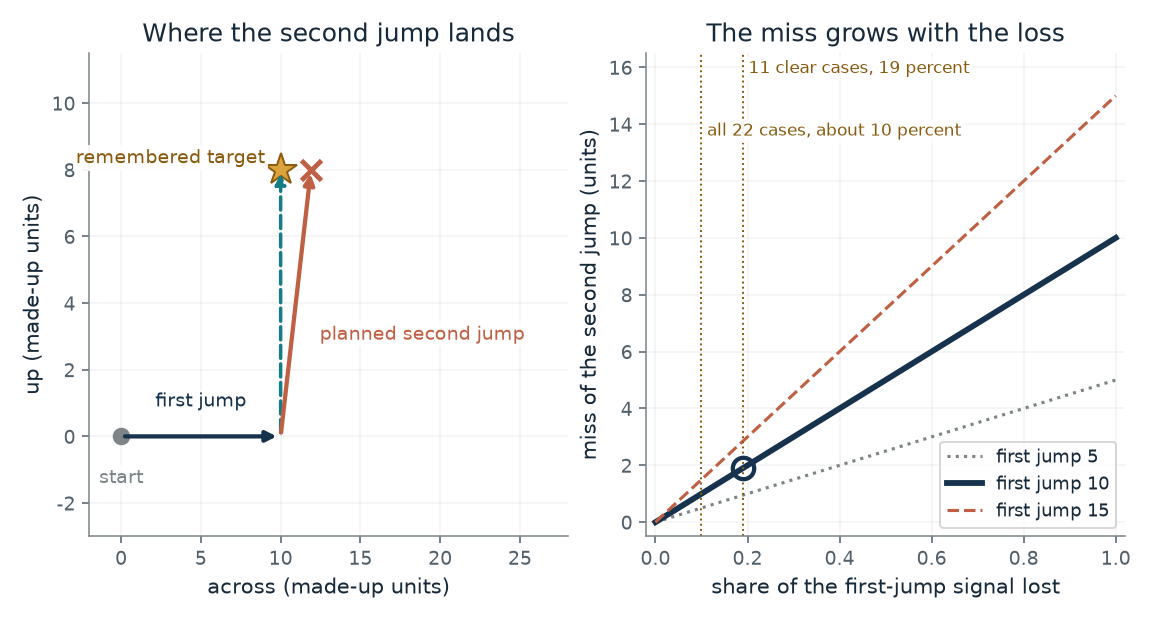

- **Planned second jump (across, up):** (1.9, 8)
- **Needed second jump (across, up):** (0, 8)
- **Miss of the end point (units):** 1.9
- **Share of the total-loss miss:** 0.19

A first jump of 10 units with 0.19 of its signal lost makes the planned second jump (1.9, 8) instead of the needed (0, 8). The end point misses by 1.9 units, 0.19 of the 10-unit miss that total loss would cause.

Estimate = (1 - 0.19) x 10 = 8.1. Plan = target - estimate = (10 - 8.1, 8 - 0) = (1.9, 8). Needed = (10 - 10, 8) = (0, 8). Miss = 0.19 x 10 = 1.9.

In [2]:
figure, values, explanation = double_step_picture(**{'deficit': 0.19, 'amplitude': 10})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How does a mind aim the second jump before the first has been seen to land?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Share of the first-jump signal lost = 1.0, First jump (units across) = 10: With the whole signal lost, the first-jump estimate is zero, so the plan is the full remembered target (10, 8) as if the eye had not moved. The end point lands 10 units too far across. The reported partial shortfalls, 10 and 19 percent, correspond to 1 and 1.9 of those units.

**Takeaway:** A missing first-jump estimate shows up as a second jump that misses by exactly the lost share times the first jump.

**Why it matters:** A controller that plans one move from the last has to know how far the last move went. The subtraction makes the dependence visible, and the shift measures how much of the estimate is being used.

**In brains and behavior:** In two monkeys, a drug in a thalamic relay shifted second jumps in the direction that losing the signal predicts, while single jumps to a lone target were barely affected. The subtraction is the book's model of what the signal does, not a recorded calculation.

**In machines:** A saccade planner or robot arm can compute the subtraction exactly from its own motor command, a specification and not a model of a monkey.

**Where it applies:** The target stays still and is remembered exactly. The first jump is estimated as a fixed share of itself. The relay in the study was partly inactivated, never shown to be off, and other pathways may carry the signal.

**Check your understanding:** The first jump is 15 units across and half the signal is lost. What is the planned second jump, and how far does it miss?

<details><summary>Show the answer</summary>

The estimate is 7.5, so the plan is (10 - 7.5, 8) = (2.5, 8) against the needed (10 - 15, 8) = (-5, 8). The end point misses by 0.5 x 15 = 7.5 units.

</details>

*Source: Chapter 20, Where a prediction could come from: a relay and the cerebellum. The subtraction m2 = r2 - s1-hat is the chapter's equation (notation added by the book). The target (10, 8), the jump sizes and the units are made up. The chapter reports the shortfall as a share: 19 percent in 11 clear cases and about 10 percent across all 22, which the authors measured as the observed shift divided by the largest shift a total loss would cause; here that share is the slider d.*

## C20-D02: If sensed feedback differs from the prediction, was it a push or a bad prediction?

A body sends a command, predicts the feedback, and senses something else. How much of that gap is an outside disturbance?

The residual is a single number, but it is the sum of two unknowns, an outside push and a prediction error. Any pair adding to the residual fits. Even a residual of zero can hide a push exactly cancelled by an opposite prediction error.

$$
e=s_{\mathrm{obs}}-f(c)=w+\left[\rho(a)-f(c)\right]
$$

**Symbols:** e: the residual, sensed feedback minus predicted feedback; f(c): the predicted feedback for a copy of the command c; rho(a): the sensory effect of the movement a actually made; w: an outside disturbance added to the feedback; rho(a) - f(c): the prediction error, how far the prediction missed the movement's own effect

**Predict before looking:** Observed 8, predicted 6. A friend says the residual of 2 proves something pushed the arm. Predict whether that is right before moving the sliders.

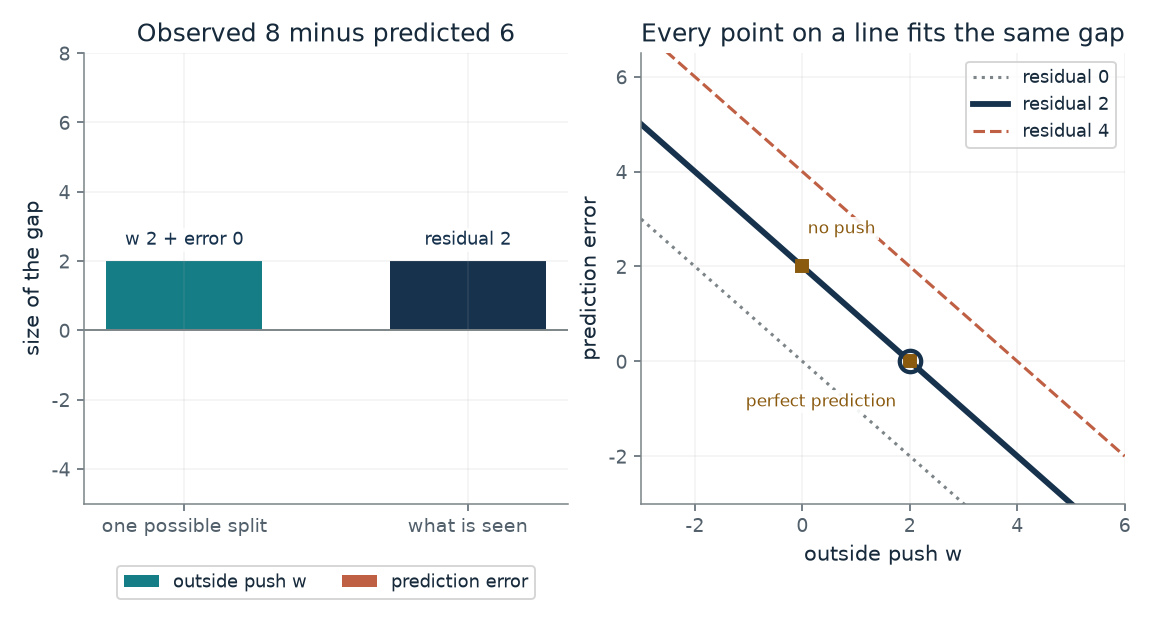

- **Observed feedback:** 8
- **Predicted feedback:** 6
- **Residual (observed minus predicted):** 2
- **Prediction error left over:** 0

Observed 8 against predicted 6 leaves a residual of 2. With an outside push of 2, the prediction must be off by 0. The same residual comes from an outside push with a perfect prediction, from no push with a prediction error, or any mix.

e = 8 - 6 = 2. e = w + [rho(a) - f(c)], so 2 = 2 + 0.

In [3]:
figure, values, explanation = residual_picture(**{'push': 2, 'residual': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='If sensed feedback differs from the prediction, was it a push or a bad prediction?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Outside push w = 0, Residual (observed minus predicted) = 2: With no push at all, the residual of 2 is entirely a prediction error: the model expected 6 and the movement's own effect was 8. The point sits at the top left of the line, and moving along the line changes the cause but not the residual.

**Takeaway:** One residual fits a whole line of causes, so a gap alone cannot say whether the world or the prediction was off.

**Why it matters:** A controller that reacts to a residual has to know whether to correct the world or its own model. The residual by itself cannot tell, so extra information is needed.

**In brains and behavior:** The additive split is a constructed explanation, not a measured equation for a circuit; the chapter reports no brain test of it.

**In machines:** A robot comparing a command's predicted sensor value with the actual reading faces the same ambiguity. Logging a second sensor or a repeated trial is the extra information.

**Where it applies:** Feedback is the movement's effect plus an additive outside push. Nothing else enters. The predicted feedback is fixed at 6.

**Check your understanding:** The observed feedback is 10 and the predicted is 6. If the outside push is 1, what is the prediction error?

<details><summary>Show the answer</summary>

The residual is 10 - 6 = 4, so the prediction error is 4 - 1 = 3.

</details>

*Source: Chapter 20, Where a prediction could come from: a relay and the cerebellum. The decomposition is the chapter's equation, called there a constructed explanation and not a measured equation for a brain circuit. The values observed 8 and predicted 6 (residual 2) are the chapter's example; the other residuals are chosen to show a zero and a larger gap.*

## C20-D03: Why does strong correction from late news make a controller swing?

If the report on position arrives 0.2 s late, how strongly can a plain feedback loop correct before it swings, and what does a model of the delay change?

The plain loop pushes toward the target with a strength proportional to how far the delayed report says it is. While the report is old, the controller keeps pushing after the target is passed, and a strong push turns the overshoot into a growing swing. The Smith loop adds what the plant has moved since the report: x(t) minus x(t minus the modelled delay). If the model is right, the loop sees the present position.

$$
x'(t)=g\,\bigl(1-x(t-\delta)\bigr)\ \text{(plain)},\qquad g\,\delta<\tfrac{\pi}{2}\ \text{to settle}
$$

**Symbols:** x: position of a simple plant whose speed equals the command; g: correction strength, the gain, per second; delta: the delay of the report, 0.2 s here; Smith loop: feedback = late report + x(t) - x(t - modelled delay); the plant model is taken as exact

**Predict before looking:** The plain loop stops settling above a gain of about 7.85 per second. Predict whether the delay-modelling loop will tolerate a gain of 10 when its delay model is exactly right.

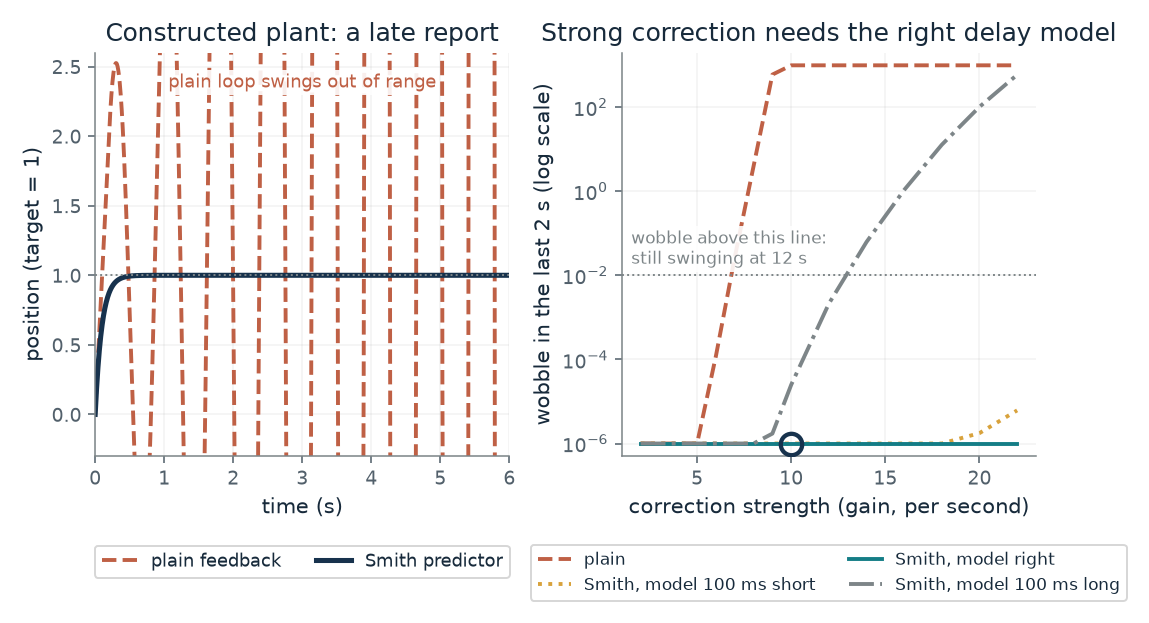

- **Plain loop:** does not settle
- **Plain overshoot (percent):** undefined (does not settle)
- **Smith loop:** settles
- **Smith overshoot (percent):** 0

At gain 10 per second with a 0.2 s delay, the plain loop does not settle and the Smith loop with its delay model 0 ms off settles. The plain loop's limit is gain pi/(2 x 0.2) = 7.85.

Plant x' = u, report x(t - 0.2). Plain: u = gain x (1 - x(t - 0.2)), which settles only when gain x delay is below pi/2, so gain below 7.85. Smith with the right delay model: the loop sees x(t) itself, so x(t) = 1 - exp(-gain x t), settling for every gain. Euler steps of 0.005 s; a loop settles if the last 2 s of a 12 s run stay within 0.01 of the target. That test is stricter than the exact bound: a swing that decays slowly, as the plain loop's does for gains near 7, is not settled by 12 s, so the figure's plain curve crosses the 0.01 line near gain 7 and not at 7.85; such a loop is labeled 'settles slowly' if a 60 s run settles. In this plant a delay model 100 ms too long settles up to about gain 15, and one 100 ms too short settles over the whole slider range, unlike the 1993 simulation as the chapter reports it, which became unstable with a model 100 ms wrong.

In [4]:
figure, values, explanation = delay_picture(**{'gain': 10, 'model_error_ms': 0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does strong correction from late news make a controller swing?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Correction strength (gain per second) = 10, Error in the delay model (ms) = 0: At gain 10 the plain loop swings out of range, while the loop that models the delay correctly rises to the target without overshoot. Now move the delay-model error to plus 100 ms: at gain 14 the swing is slow to die away, and at gain 20 the delay-modelling loop fails too (the limit with this error is roughly 15 per second). The chapter says a delay model wrong by 100 ms made the 1993 simulation unstable; this constructed plant tolerates that error at lower gains, so it does not reproduce that result.

**Takeaway:** A model of the delay allows strong correction in this constructed plant and tolerates a modest delay-model error here, but a large enough gain still fails when the delay model is 100 ms too long. The chapter's source simulation was less forgiving: a delay model wrong by 100 ms made it unstable.

**Why it matters:** Strong correction from old data is the cause of the swing. A controller that holds a prediction of the present can act on it and use the late report as a check, which is what the cerebellum proposal says might happen.

**In brains and behavior:** The 1993 paper proposed, with a simulation and no experiment, that the cerebellum holds a forward model and a delay model. A 2007 magnetic-pulse experiment fits a hand estimate 138 ms old, but nothing here tests a cerebellum.

**In machines:** A Smith predictor is an engineering controller for processes with long delays. It is a specification, not a model of any brain.

**Where it applies:** A pure integrator plant, no noise, an exact plant model, and a delay model that is exactly right or off by 100 ms. The plain loop settles only when gain times delay is below pi/2. Real delays and plants differ. In this plant a delay model that is 100 ms too long still settles at gains up to about 15 per second, and one 100 ms too short settles over the whole slider range. The 1993 simulation, as the chapter reports it, became unstable with a delay model 100 ms wrong; this constructed integrator is more forgiving, so its tolerance is not a result about that paper or about any brain.

**Check your understanding:** The report is 0.2 s late. What is the plain loop's largest gain that still settles?

<details><summary>Show the answer</summary>

Gain times delay must be below pi/2, so the gain must be below pi/(2 x 0.2) = 7.85 per second.

</details>

*Source: Chapter 20, Where a prediction could come from: a relay and the cerebellum. The shower story and the Smith predictor idea are the chapter's. The plant, the 0.2 s delay (the low end of the chapter's 200 to 250 ms upper estimate for sight-guided reaches), the gains and the simulation are constructed here and are not the 1993 paper's simulation, and they give a different answer for a 100 ms delay-model error: the chapter reports that error made the 1993 simulation unstable, while here it is tolerated up to about gain 15 (model too long) or at every slider gain (model too short). Euler steps of 5 ms.*

## C20-D04: Why does a skilled hand correct some errors and let others go?

If a controller pays for effort and for missing the task, how much does it correct a direction that hardly matters?

Each step, a push moves the state. The controller can undo a share K of the error at an effort cost. If the error does not affect the task, the weight q is small, K is small, and the error is allowed to drift to a larger long-run spread. With zero weight there is no correction and the spread grows without a long-run limit.

$$
P=\frac{q+\sqrt{q^{2}+4qr}}{2},\qquad K=\frac{P}{P+r},\qquad \operatorname{Var}=\frac{\sigma^{2}}{K(2-K)}
$$

**Symbols:** q: weight on missing the task in one direction; r: cost of the correcting effort; P: the steady-state cost-to-go weight of the standard scalar solution; K: the share of the error corrected each step; Var: long-run variance, with a push of variance sigma^2 = 1 added each step

**Predict before looking:** If a direction carries no weight at all, how large is its long-run spread? And does giving it the same weight as the other direction equalize the two?

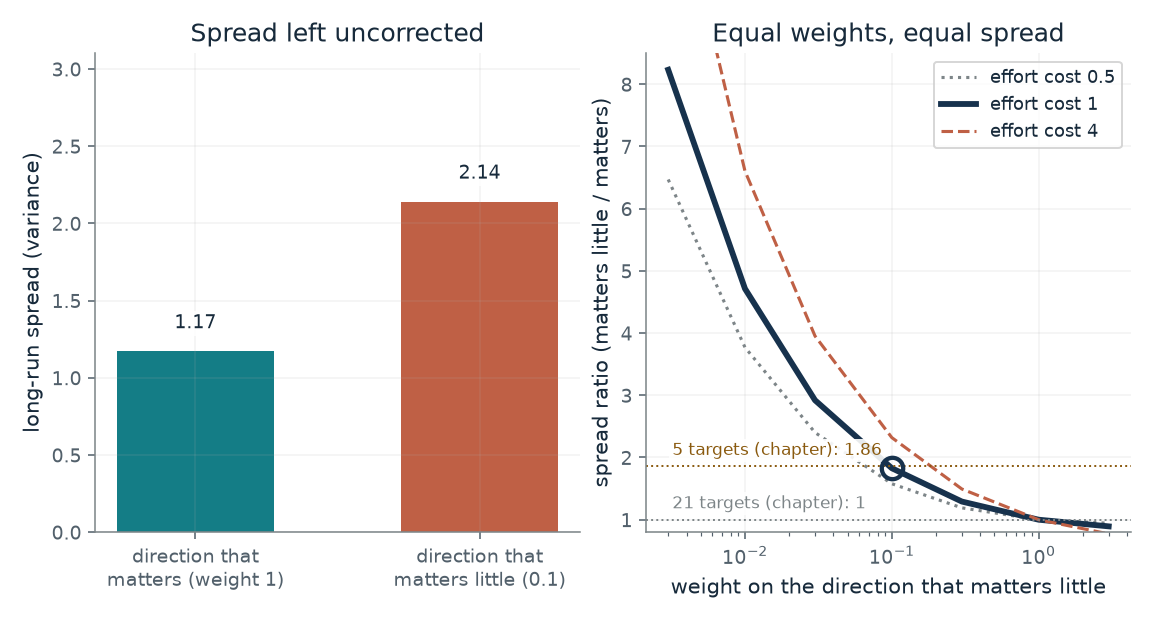

- **Gain, direction that matters:** 0.618
- **Gain, direction that matters little:** 0.27
- **Spread, direction that matters:** 1.17
- **Spread ratio (matters little / matters):** 1.83

A direction weighted 0.1 gets gain 0.27 and spread 2.14, against gain 0.618 and spread 1.17 for the direction that matters. The ratio is 1.83; at equal weights it is 1. The model is constructed, not fitted to the study.

P = (q + sqrt(q^2 + 4 q r))/2 and gain K = P/(P + r). For q = 1, r = 1: K = 0.618. For q = 0.1: K = 0.27. Spread = 1/(K(2 - K)) = 1.17 and 2.14. At some settings the ratio lands near the chapter's 0.26/0.14 = 1.86 only by coincidence; the weights are made up and nothing is fitted.

In [5]:
figure, values, explanation = minimal_picture(**{'irrelevant_weight': 0.1, 'effort_cost': 1.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why does a skilled hand correct some errors and let others go?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Weight on the direction that matters little = 0.1, Effort cost r = 1.0: At weight 0.1 against 1, the spread in the direction that matters little is about 1.83 times the other, near 1.86, the ratio of the chapter's two five-target variances, 0.26 over 0.14. The nearness of 1.83 to 1.86 is a coincidence of a tidy number, not a fit: the weights are made up and the study's spreads are not what this model computes. Set the weight to 1 and the two spreads are equal, the analogue of the 21-target condition where every point on the path was a target.

**Takeaway:** A controller that charges for effort corrects the direction that matters hard and the other loosely; at equal weights the two are equal.

**Why it matters:** Perfect correction everywhere is costly. A controller that corrects only what interferes with the task spends effort where it pays, so a looser hand between targets is a prediction, not a defect.

**In brains and behavior:** Todorov and Jordan present this as a theory with simulations and experiments. It names no circuit and does not explain how skill is acquired.

**In machines:** An optimal feedback controller is a specification: choose the cost, and the gain follows. A robot arm can be built to correct only what the task needs.

**Where it applies:** A one-number state, a push of fixed size each step, a quadratic cost and a controller that knows the state. Real reaches have many joints, delayed noisy senses and no single weight. In the study, the 21-target comparison no longer detected a significant difference. The study's spreads are of hand position at points along a reach, while the model's ratio compares two long-run directions of a one-number state, so the two ratios are different kinds of quantity.

**Check your understanding:** At effort cost 1 and weight 1, K = 0.618. What long-run variance does that give?

<details><summary>Show the answer</summary>

Var = 1/(0.618 x (2 - 0.618)) = 1/(0.618 x 1.382) = 1.17.

</details>

*Source: Chapter 20, Which errors to fix, and how a body model is repaired. The principle (correct deviations only when they interfere with the task) and the spreads 0.14 and 0.26 square centimeters with five targets, and 0.18 and 0.18 with 21, are quoted from the chapter's account of Todorov and Jordan (2002). The scalar model, its weights and its noise are constructed here; nothing is fitted to the study, and the ratio 0.26/0.14 = 1.86 of the chapter's two five-target variances is drawn only as a reference line.*

## C20-D05: Why do reaches bend the other way when a force is switched off?

If a controller builds a model of a push from its errors, how closely does the aftereffect mirror the first miss, and how does that depend on practice?

Each reach corrects the estimate by a share of the miss. With the field on, the miss shrinks as the estimate approaches the push. When the field is removed, the estimate is still near the old push, so the arm compensates for a push that is no longer there, and the miss has the opposite sign.

$$
b_{n+1}=b_n+\eta\,(B-b_n),\qquad b_n=B\bigl(1-(1-\eta)^{n}\bigr),\qquad \text{aftereffect}=-b_N
$$

**Symbols:** B: the strength of the push of the world, taken as 1; b_n: the controller's estimate of the push after n reaches; eta: learning rate, the share of the error corrected in the estimate each reach; N: the number of practice reaches with the field on

**Predict before looking:** After practice with a learning rate of 0.1, what is the first miss when the field is switched off, compared with the very first miss?

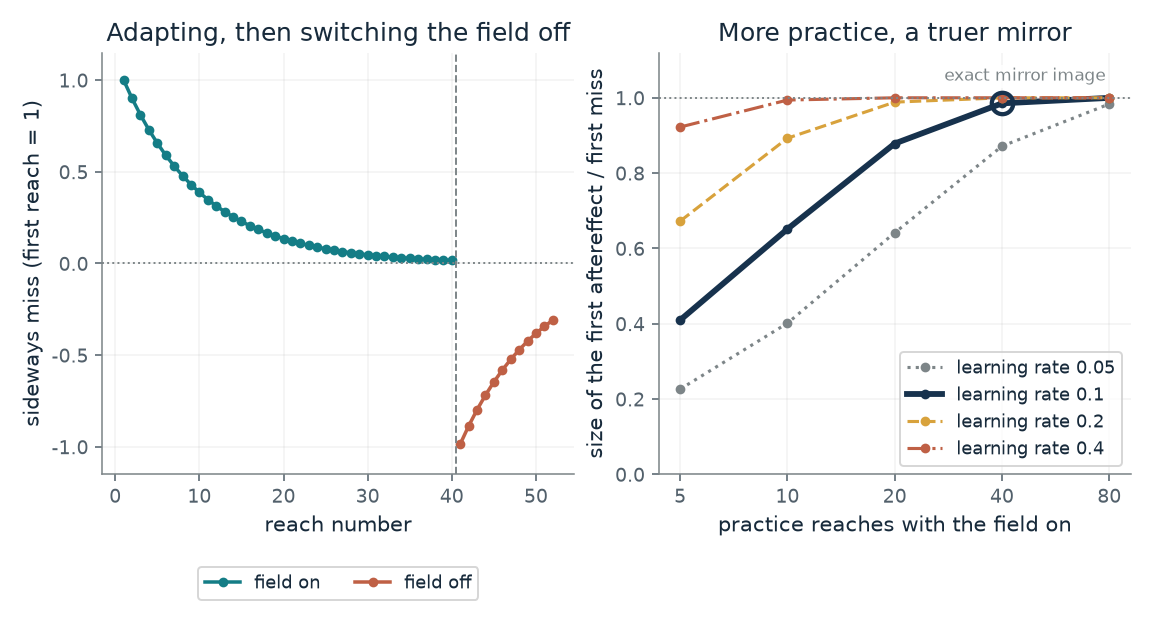

- **First miss (field on):** 1
- **First reach after the field goes off:** -0.985
- **Aftereffect as a share of the first miss:** 0.985
- **Miss left on the last practice reach:** 0.0164

With learning rate 0.1 and 40 practice reaches, the model's field estimate reaches 0.985 of the true field. The first reach after the field is removed misses by 0.985, on the opposite side from the first miss of 1. This is a constructed update rule, not the paper's model.

Estimate after n reaches = 1 - (1 - 0.1)^n. After 40: 1 - 0.9^40 = 0.985. Miss with the field on = 1 - estimate; first miss with it off = 0 - estimate = -0.985.

In [6]:
figure, values, explanation = adaptation_picture(**{'rate': 0.1, 'practice': 40})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='Why do reaches bend the other way when a force is switched off?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Learning rate = 0.1, Practice reaches with the field on = 40: After 40 reaches at learning rate 0.1 the estimate has reached 98.5 percent of the push, so the first reach with the field off misses by almost exactly the size of the first miss, on the opposite side. With 5 reaches the mirror is only 41 percent.

**Takeaway:** The better the estimate of the push, the more nearly the aftereffect mirrors the first miss; the mirror is a sign of what was learned.

**Why it matters:** A controller that adapts has built a model, and a model keeps predicting a push that is gone. The aftereffect is therefore read as a sign of the model, inferred from behavior.

**In brains and behavior:** The authors read the aftereffect as a sign that the controller gradually built a model of the field. That is an inference from behavior, not a recorded model.

**In machines:** A robot arm can run the same error-driven update on a force estimate; the update rule is a specification.

**Where it applies:** The miss is proportional to the gap between the true push and the estimate, the estimate is updated from the last miss only, and the field is one steady push. Real reaches have trial-to-trial noise and several forces.

**Check your understanding:** At learning rate 0.2 and 10 practice reaches, how close is the estimate to the push?

<details><summary>Show the answer</summary>

1 - 0.8^10 = 1 - 0.107 = 0.893, so the aftereffect is 89 percent of the first miss.

</details>

*Source: Chapter 20, Which errors to fix, and how a body model is repaired. The sequence of events (early distortion, practice back to near free-space paths, aftereffects that were approximately mirror images) is the chapter's account of Shadmehr and Mussa-Ivaldi (1994), which it draws as a schematic. The update rule, the learning rates and the trial counts are constructed here; nothing is a measurement or the paper's model.*

## C20-D06: What can 2 successes in 10 trials tell us?

If a robot hand completed a task in 2 of 10 real trials, how well does that pin down its success rate, and what would 0 of 10 tell?

For each possible true rate, the chance of seeing a given count is a binomial probability. A rate is ruled out when it would make the count of 2 or fewer, or 2 or more, rare. The rates that survive form an interval. The exact interval is wide because ten trials contain little information.

$$
P(X\le k\mid p)=\sum_{i=0}^{k}\binom{n}{i}p^{i}(1-p)^{n-i}
$$

**Symbols:** n: number of trials, 10; k: number of successes; p: the underlying success rate, unknown; range: the rates not ruled out at 95 percent, found by exact search

**Predict before looking:** With 0 successes in 10 trials, predict whether a true success rate of 25 percent is ruled out.

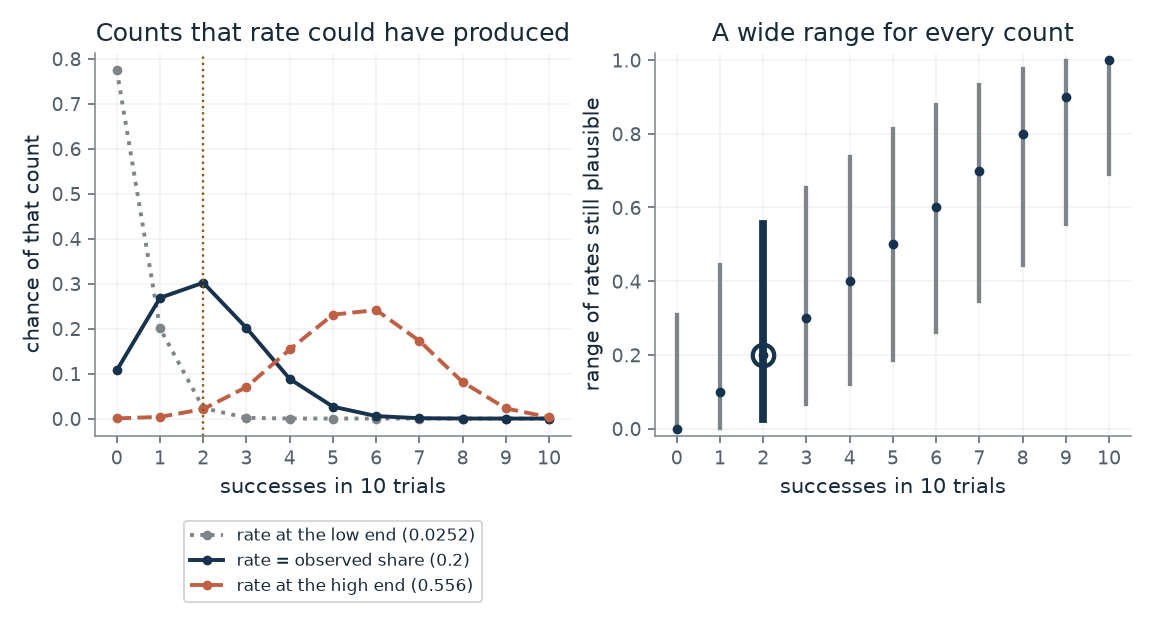

- **Share of trials:** 0.2
- **Low end of the 95 percent range:** 0.0252
- **High end of the 95 percent range:** 0.556
- **Width of the range:** 0.531

2 successes in 10 trials is a share of 0.2, but rates from 0.0252 to 0.556 remain plausible at 95 percent. The range is 0.531 wide, so ten trials cannot separate nearby rates.

Exact (Clopper-Pearson) range: the lowest rate that gives 2 or more successes with chance at least 0.025 is 0.0252; the highest rate that gives 2 or fewer with chance at least 0.025 is 0.556.

In [7]:
figure, values, explanation = counts_picture(**{'successes': 2})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What can 2 successes in 10 trials tell us?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Successes in 10 trials = 2: Two of ten gives a share of 0.2, but rates from about 0.025 to 0.556 remain plausible at 95 percent. Move to 0 of 10: the high end falls to about 0.31, so 25 percent is not ruled out, but 50 percent is.

**Takeaway:** Ten trials leave a wide range of rates plausible, so the two reported counts are consistent with a wide range of true rates, including some in common.

**Why it matters:** A system that is evaluated on a handful of real trials cannot be told apart from many nearby rates. The honest report is the count and its range, not the share alone.

**In brains and behavior:** The chapter's brain-side counts are also small: one participant in the walking study, eight men in the unseen-hand test, two monkeys in the eye-jump study, and eight people in the reaching-variance test. The same caution applies to any share computed from them.

**In machines:** A robot test on 10 trials is a measurement with this much uncertainty. The 2019 preprint's hand-tuned simulation settings are a separate matter.

**Where it applies:** The 10 trials are independent with one success rate each. The ranges describe those trials only; they do not say the trials were representative of other starts or sequences. The chapter's other numbers are likewise from small samples.

**Check your understanding:** For 0 successes in 10, the high end of the range is 1 - 0.025^(1/10). What is it?

<details><summary>Show the answer</summary>

0.025^(0.1) = 0.6915, so the high end is 1 - 0.6915 = 0.308.

</details>

*Source: Chapter 20, Which errors to fix, and how a body model is repaired. The counts come from the chapter's account of the 2019 Rubik's cube preprint: in 10 real trials starting with a solved cube and one fixed scrambling sequence, the hand completed it in 2 of 10 with a cube carrying its own sensors and in 0 of 10 when the cube's state was estimated from cameras. The preprint's own tests are not reproduced; the exact ranges are computed here from those counts.*

## Bring it to your own question

Ask for the delay, the gain, and what the predicted feedback is. For a plan from a remembered target, subtract the estimated last move. For a gap between prediction and sensor, say that the residual alone cannot name its cause. For late feedback, compare the plain loop with a loop that models the delay, and for a changed world use an error-driven update and check the aftereffect. Quote counts with their exact range.

Use the `mmi-ch20-acting-through-body` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.